In [1]:
import os
import pandas as pd
import numpy as np
import datetime
import warnings
import calendar
import glob
warnings.simplefilter(action='ignore', category=FutureWarning)
import itertools
from scipy.stats import skew
import statsmodels.api as sm
import scipy.stats
from scipy.optimize import differential_evolution
from multiprocessing import Pool
import scipy.special
import numba
from concurrent.futures import ProcessPoolExecutor, as_completed
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from netCDF4 import Dataset
from matplotlib.gridspec import GridSpec
from scipy.stats import genextreme as gev
import seaborn as sns
from convertbng.util import convert_bng, convert_lonlat

In [2]:
def simulate_storms(month_lengths, simulation_length, parameters, rng):
    simulation_end_time = np.cumsum(month_lengths)[-1]

    sim_len_ext = simulation_length + 4
    month_lengths_ext = month_lengths.copy()
    for _ in range(4):
        month_lengths_ext = np.concatenate([month_lengths_ext, month_lengths[-12:]])

    lamda = np.tile(parameters['lamda'].values, sim_len_ext)
    cumulative_expected_storms = np.cumsum(lamda * month_lengths_ext)
    cumulative_month_endtimes = np.cumsum(month_lengths_ext)
    expected_number_of_storms = cumulative_expected_storms[-1]
    number_of_storms = rng.poisson(expected_number_of_storms)

    deformed_arrivals = expected_number_of_storms * np.sort(rng.uniform(size=number_of_storms))
    cumulative_expected_storms = np.insert(cumulative_expected_storms, 0, 0.0)
    cumulative_month_endtimes = np.insert(cumulative_month_endtimes, 0, 0.0)
    interpolator = scipy.interpolate.interp1d(
        cumulative_expected_storms, cumulative_month_endtimes
    )
    storm_arrival_times = interpolator(deformed_arrivals)

    storm_arrival_times = storm_arrival_times[storm_arrival_times < simulation_end_time]
    number_of_storms = storm_arrival_times.shape[0]
    storms = pd.DataFrame({
        'storm_id': np.arange(number_of_storms),
        'storm_arrival': storm_arrival_times
    })
    storms['month'] = lookup_months(month_lengths, simulation_length, storms['storm_arrival'].values)
    return storms, number_of_storms


def lookup_months(month_lengths, period_length, times):
    end_times = np.cumsum(month_lengths)
    repeated_months = np.tile(np.arange(1, 13, dtype=int), period_length)
    idx = np.digitize(times, end_times)
    return repeated_months[idx]


def simulate_raincells_point(storms, parameters, rng):
    tmp = pd.merge(storms, parameters, how='left', on='month')
    tmp.sort_values(['storm_id'], inplace=True)

    number_of_raincells = rng.poisson(tmp['nu'].values)
    storm_ids, storm_arrivals, storm_months = make_storm_arrays_by_raincell(
        number_of_raincells,
        storms['storm_id'].values,
        storms['storm_arrival'].values,
        storms['month'].values
    )
    return pd.DataFrame({
        'storm_id': storm_ids,
        'storm_arrival': storm_arrivals,
        'month': storm_months
    })


def make_storm_arrays_by_raincell(num_cells, storm_ids, storm_arrivals, storm_months):
    return (
        np.repeat(storm_ids, num_cells),
        np.repeat(storm_arrivals, num_cells),
        np.repeat(storm_months, num_cells)
    )


def merge_parameters(df, month_lengths, simulation_length, parameters):
    df['month'] = lookup_months(month_lengths, simulation_length, df['storm_arrival'].values)
    parameters_subset = parameters.drop(
        ['fit_stage', 'converged', 'objective_function',
         'iterations', 'function_evaluations'],
        axis=1, errors='ignore'
    )
    return pd.merge(df, parameters_subset, how='left', on='month')


def main_point_model_monthly(parameters,simulation_length,month_lengths,intensity_distribution,rng):
    """
    NSRP point model simulation (monthly parameters).

    Args:
        parameters (pandas.DataFrame): Parameters dataframe from fitting (must include 'month', 'lamda', 'beta', 'nu', 'eta', 'theta', etc.).
        simulation_length (int): Number of years to simulate.
        month_lengths (numpy.ndarray): Hours in each month to be simulated.
        intensity_distribution (str): Raincell intensity distribution ('exponential', 'weibull', 'generalised_gamma').
        rng (numpy.random.Generator): Random number generator.

    Steps:
        1. Simulate storms (temporal Poisson process).
        2. Simulate raincells for each storm.
        3. Simulate raincell arrival times.
        4. Simulate raincell durations.
        5. Simulate raincell intensities.
    """

    # Ensure dataframe is sorted by month
    parameters = parameters.copy()
    parameters.sort_values(by='month', inplace=True)

    # Step 1 - Simulate storms
    storms, number_of_storms = simulate_storms(month_lengths, simulation_length, parameters, rng)

    # Step 2 - Simulate raincells
    df = simulate_raincells_point(storms, parameters, rng)

    # Merge parameters into master dataframe
    df = pd.merge(df, parameters, how='left', on='month')

    # Step 3 - Raincell arrival times
    raincell_arrival_times = rng.exponential(1.0 / df['beta'])  # relative to storm origin
    df['raincell_arrival'] = df['storm_arrival'] + raincell_arrival_times

    # Step 4 - Raincell durations
    df['raincell_duration'] = rng.exponential(1.0 / df['eta'])
    df['raincell_end'] = df['raincell_arrival'] + df['raincell_duration']

    # Step 5 - Raincell intensities
    if intensity_distribution == 'exponential':
        df['raincell_intensity'] = rng.exponential(df['theta'])
    elif intensity_distribution == 'weibull':
        df['raincell_intensity'] = scipy.stats.weibull_min.rvs(
            c=df['kappa'], scale=df['theta'], random_state=rng
        )
    elif intensity_distribution == 'generalised_gamma':
        df['raincell_intensity'] = scipy.stats.gengamma.rvs(
            a=(df['kappa_1'] / df['kappa_2']), c=df['kappa_2'],
            scale=df['theta'], random_state=rng
        )

    # Clean up parameters from output (optional)
    df.drop(columns=['lamda', 'beta', 'rho', 'eta', 'gamma', 'theta', 'kappa'],
            inplace=True, errors='ignore')

    return df


def initialise_discrete_rainfall_arrays_point(n_timesteps):
    """
    Create zero-filled array for point rainfall output.

    Args:
        n_timesteps (int): Total number of timesteps in the simulation.

    Returns:
        dict: {'point': np.ndarray of shape (n_timesteps, 1)}
    """
    return {'point': np.zeros((n_timesteps, 1))}



def discretise_point(period_start_time, timestep_length,raincell_arrival_times, raincell_end_times,
                     raincell_intensities, discrete_rainfall):
    """
    Convert raincells into discrete timestep rainfall totals.

    Args:
        period_start_time (float): Simulation start time in hours.
        timestep_length (float): Length of each timestep in hours.
        raincell_arrival_times (np.ndarray): Raincell start times in hours.
        raincell_end_times (np.ndarray): Raincell end times in hours.
        raincell_intensities (np.ndarray): Raincell intensities (mm/hr).
        discrete_rainfall (np.ndarray): Array to store output (modified in place).
    """
    discrete_rainfall.fill(0.0)  # Reset to zero before filling

    for idx in range(raincell_arrival_times.shape[0]):
        # Times relative to simulation/block start
        rc_arrival_time = raincell_arrival_times[idx] - period_start_time
        rc_end_time = raincell_end_times[idx] - period_start_time
        rc_intensity = raincell_intensities[idx]

        # Timesteps covered
        rc_arrival_timestep = int(np.floor(rc_arrival_time / timestep_length))
        rc_end_timestep = int(np.floor(rc_end_time / timestep_length))

        # Distribute intensity across affected timesteps
        for timestep in range(rc_arrival_timestep, rc_end_timestep + 1):
            timestep_start_time = timestep * timestep_length
            timestep_end_time = (timestep + 1) * timestep_length
            effective_start = max(rc_arrival_time, timestep_start_time)
            effective_end = min(rc_end_time, timestep_end_time)
            timestep_coverage = effective_end - effective_start

            if timestep < discrete_rainfall.shape[0] and timestep_coverage > 0:
                discrete_rainfall[timestep, 0] += rc_intensity * timestep_coverage


def get_storm_depths_point(df):
    """
    Summarise storm total depth and duration from raincell dataframe.

    Args:
        df (pd.DataFrame): NSRP raincell output with columns:
            ['storm_id', 'storm_arrival', 'month', 'raincell_duration', 'raincell_intensity', 'raincell_end']

    Returns:
        pd.DataFrame: Storm-level statistics.
    """
    df['raincell_depth'] = df['raincell_duration'] * df['raincell_intensity']

    storm_stats = df.groupby(['storm_id']).agg({
        'storm_arrival': 'min',
        'month': 'min',
        'raincell_depth': 'sum',
        'raincell_end': 'max'
    }).reset_index()

    storm_stats.rename(columns={'raincell_depth': 'storm_depth',
                                'raincell_end': 'storm_end'}, inplace=True)
    storm_stats['storm_duration'] = storm_stats['storm_end'] - storm_stats['storm_arrival']
    storm_stats.drop(columns=['storm_end'], inplace=True)

    return storm_stats


def discretise_by_point_monthly(df_raincells, simulation_length_years, STARTYR, timestep_length=24.0):
    # Input: timestep_length in hours (default 24 -> produce daily totals)
    Start = pd.to_datetime(str(STARTYR)+str('-01-01 00:00:00'),format='%Y-%m-%d %H:%M:%S')
    End = pd.to_datetime(str(STARTYR+simulation_length_years-1)+str('-12-31 23:00:00'),format='%Y-%m-%d %H:%M:%S')
    DatesVect = pd.date_range(start=Start, end=End, freq="D")
    monthly_df = pd.DataFrame({'Year': DatesVect.year, 'Month': DatesVect.month})
    HRCOUNT = monthly_df.groupby(['Year', 'Month']).size().reset_index(name='n_days')
    month_days = HRCOUNT['n_days'].to_numpy()

    # number of timesteps per month given timestep_length (hours)
    timesteps_per_month = (month_days * 24 / timestep_length).astype(int)  # usually days if timestep_length==24
    total_timesteps = timesteps_per_month.sum()

    # Create discrete output at the requested timestep resolution
    discrete_rainfall = np.zeros((total_timesteps, 1))

    # Loop months and use hours-based start/end for mask
    start_ts = 0
    start_hour = 0.0
    for m_idx, days_in_month in enumerate(month_days):
        hours_in_month = days_in_month * 24.0
        end_hour = start_hour + hours_in_month
        end_ts = start_ts + timesteps_per_month[m_idx]

        # mask must compare hours to hours
        mask = ((df_raincells['raincell_arrival'] < end_hour) & (df_raincells['raincell_end'] > start_hour))
        raincells_month = df_raincells.loc[mask]

        # slice the output array corresponding to this month (timesteps, 1)
        discretise_point(
            period_start_time=start_hour,
            timestep_length=timestep_length,
            raincell_arrival_times=raincells_month['raincell_arrival'].values,
            raincell_end_times=raincells_month['raincell_end'].values,
            raincell_intensities=raincells_month['raincell_intensity'].values,
            discrete_rainfall=discrete_rainfall[start_ts:end_ts]
        )

        # advance
        start_hour = end_hour
        start_ts = end_ts

    return discrete_rainfall


def initialise_hourly_array(total_hours):
    # One column for point model, all zeros initially
    return np.zeros((total_hours, 1), dtype=float)

In [3]:
predictors = {('temp_avg', 'DDD'): ['temp_avg_lag1'],
        ('temp_avg', 'DD'): ['temp_avg_lag1'],
        ('temp_avg', 'DW'): ['temp_avg_lag1', 'prcp'],
        ('temp_avg', 'WD'): ['temp_avg_lag1', 'prcp_lag1'],
        ('temp_avg', 'WW'): ['temp_avg_lag1'],
        ('dtr', 'DDD'): ['dtr_lag1'],
        ('dtr', 'DD'): ['dtr_lag1'],
        ('dtr', 'DW'): ['dtr_lag1', 'prcp'],
        ('dtr', 'WD'): ['dtr_lag1', 'prcp_lag1'],
        ('dtr', 'WW'): ['dtr_lag1'],
        ('vap_press', 'DDD'): ['vap_press_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('vap_press', 'DD'): ['vap_press_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('vap_press', 'DW'): ['vap_press_lag1', 'prcp', 'temp_avg', 'dtr'],
        ('vap_press', 'WD'): ['vap_press_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('vap_press', 'WW'): ['vap_press_lag1', 'prcp', 'temp_avg', 'dtr'],
        ('wind_speed', 'DDD'): ['wind_speed_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('wind_speed', 'DD'): ['wind_speed_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('wind_speed', 'DW'): ['wind_speed_lag1', 'prcp', 'temp_avg', 'dtr'],
        ('wind_speed', 'WD'): ['wind_speed_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('wind_speed', 'WW'): ['wind_speed_lag1', 'prcp', 'temp_avg', 'dtr'],
        ('sun_dur', 'DDD'): ['sun_dur_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('sun_dur', 'DD'): ['sun_dur_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('sun_dur', 'DW'): ['sun_dur_lag1', 'prcp', 'temp_avg', 'dtr'],
        ('sun_dur', 'WD'): ['sun_dur_lag1', 'temp_avg', 'dtr'],  # 'prcp',
        ('sun_dur', 'WW'): ['sun_dur_lag1', 'prcp', 'temp_avg', 'dtr']}
        
def aggregate_rainfall(x, n_points, window_size):
    """
    Aggregate hourly rainfall to daily totals (sum over each 24-hour period).
    Handles both DataFrame and NumPy array inputs.
    """
    # Convert DataFrame to numeric numpy array if needed
    if isinstance(x, pd.DataFrame):
        # keep only numeric columns
        x = x.select_dtypes(include=[np.number]).to_numpy()

    n_days = x.shape[0] // window_size
    y = np.zeros((n_days, n_points))
    i = 0
    for d in range(n_days):
        y[d, :] = np.sum(x[i:i + window_size, :], axis=0)
        i += window_size
    return y


def day_of_year(year, month):
    if check_if_leap_year(year):
        pseudo_year = 2000
    else:
        pseudo_year = 2001

    doy_list = []
    d = datetime.datetime(pseudo_year, month, 1, 0)
    while (d.year == pseudo_year) and (d.month == month):
        doy_list.append(d.timetuple().tm_yday)
        d += datetime.timedelta(days=1)
    doy_array = np.asarray(doy_list)

    return doy_array

def check_if_leap_year(year):
    if year % 4 == 0:
        if year % 100 == 0:
            if year % 400 == 0:
                leap_year = True
            else:
                leap_year = False
        else:
            leap_year = True
    else:
        leap_year = False
    return leap_year



@numba.jit(nopython=True)
def regressions(n_days, season_length, month, variable, sn_sample, ri, transition_key, z_scores, output_type, transitions,
        parameters, pool_id, predictors, interpolated_parameters, residuals,):
    for day in range(1, n_days + 1):

        # Identify season based on month (argument) and day of month if using half-months
        if season_length == 'month':
            season = month
        elif season_length == 'half-month':
            if day <= 15:  # TODO: Check looping days here and getting half-months correct (hardcoded)
                season = (month - 1) * 2 + 1
            else:
                season = (month - 1) * 2 + 2

        # Prepare (simulate) standard normal residual/error term
        # residuals = self.rng.standard_normal(1)[0]  # !221209
        residuals[:] = sn_sample[ri]  # !221209

        # Prediction of standardised anomalies
        # - day loop starts with one
        # - only 31 days in transitions array (i.e. current month)
        # - first value to store is in position 2
        for transition_id, transition_name in transition_key.items():

            key_param = (pool_id, season, variable, transition_name)
            if key_param not in parameters:
                raise KeyError("Missing regression parameters")
        
            key_pred = (variable, transition_name)
            if key_pred not in predictors:
                raise KeyError("Missing predictors")
        
            key_se = ('se', output_type, variable, season, transition_name)
            if key_se not in interpolated_parameters:
                raise KeyError("Missing interpolated parameters")
        
            # Intercept
            z_scores[(output_type, variable)][day + 1, :] = np.where(
                transitions[day - 1, :] == transition_id,
                parameters[key_param][0],
                z_scores[(output_type, variable)][day + 1, :]
            )
        
            # Multiplicative terms
            i = 1
            for predictor in predictors[key_pred]:
                if predictor.endswith('_lag1'):
                    predictor_variable = predictor.replace('_lag1', '')
                    lag = 1
                else:
                    predictor_variable = predictor
                    lag = 0
        
                if predictor_variable != 'na':
                    z_scores[(output_type, variable)][day + 1, :] += np.where(
                        transitions[day - 1, :] == transition_id,
                        parameters[key_param][i]
                        * z_scores[(output_type, predictor_variable)][day + 1 - lag, :],
                        0.0
                    )
                i += 1
        
            # Scale residual/error term by standard error
            residuals *= np.where(
                transitions[day - 1, :] == transition_id,
                interpolated_parameters[key_se],
                1.0
            )

        # Add residual/error component
        z_scores[(output_type, variable)][day + 1, :] += residuals

        # Increment counter (index place) for standard normal sample
        ri += 1

    return z_scores[(output_type, variable)][2:, :], ri


def calculate_pet2(year, month,output_types,values,discretisation_metadata,n_points,latitude,wind_height):

    # Alternate version of calculate_pet which is not used currently but can be employed if user wishes to 
    doy = day_of_year(year, month)
    n_days = doy.shape[0]
    
    for output_type in output_types:

        # Derive minimum and maximum temperatures and convert temperatures from [C] to [K]
        tmax = (values[(output_type, 'temp_avg')][2:2+n_days, :] + 0.5 * values[(output_type, 'dtr')][2:2+n_days, :])
        tmin = (values[(output_type, 'temp_avg')][2:2+n_days, :] - 0.5 * values[(output_type, 'dtr')][2:2+n_days, :])
        tmax += 273.15
        tmin += 273.15
        tavg = values[(output_type, 'temp_avg')][2:2+n_days, :] + 273.15
        elev = discretisation_metadata[(output_type, 'z')]
        pres = 101.3 * (((293.0 - (0.0065 * elev)) / 293.0) ** 5.26)
        avp = values[(output_type, 'vap_press')][2:2+n_days, :]
        avp = np.maximum(avp, 0.000001)
        
        svp_tmin = 0.6108 * np.exp((17.27 * (tmin - 273.15)) / ((tmin - 273.15) + 237.3))
        svp_tmax = 0.6108 * np.exp((17.27 * (tmax - 273.15)) / ((tmax - 273.15) + 237.3))
        svp = 0.5 * (svp_tmin + svp_tmax)

        dsvp = ((4098.0 * (0.6108 * np.exp((17.27 * (tavg - 273.15)) / ((tavg - 273.15) + 237.3)))) / (((tavg - 273.15) + 237.3) ** 2))
        dr = 1.0 + (0.033 * np.cos(((2.0 * np.pi) / 365.0) * doy)) 
        dec = 0.409 * np.sin((((2.0 * np.pi) / 365.0) * doy) - 1.39) 
        dr = dr[:, None]  # adds a second dimension
        dec = dec[:, None]
        lat = np.zeros((doy.shape[0], n_points[output_type]))  
        lat.fill(latitude)
        omega = np.arccos(-1 * np.tan(lat) * np.tan(dec))
        ra = (((24.0 * 60.0) / np.pi) * 0.0820 * dr * ((omega * np.sin(lat) * np.sin(dec)) + (np.cos(lat) * np.cos(dec) * np.sin(omega)))) 
        N = 24 / np.pi * omega

        SunshineHours = values[(output_type, 'sun_dur')][2:2+n_days, :]
        rs = (0.25 + 0.5 * (np.minimum(SunshineHours, N) / N)) * ra  
        rns = 0.77 * rs  
        rso = (0.75 + (0.00002 * discretisation_metadata[(output_type, 'z')])) * ra
        rnl = ((4.903 * 10 ** -9) * ((tmin ** 4.0 + tmax ** 4.0) / 2.0) * (0.34 - (0.14 * (avp ** 0.50))) * ((1.35 * (rs / rso)) - 0.35))
        netrad = rns - rnl

        Windspeed = values[(output_type, 'wind_speed')][2:2+n_days, :]

        # - adjustment from 10 to 2m is required for MIDAS data
        if wind_height != 2.0:
            ws2 = Windspeed * (4.87 / (np.log((67.8 * float(wind_height)) - 5.42)))
        else:
            ws2 = Windspeed

        # Assume soil heat flux of zero at daily timestep (FAO56 equation 42)
        shf = 0.0
        psy = 0.000665 * pres
        # Calculate ET0 [mm day-1]
        et0 = (((0.408 * dsvp * (netrad - shf)) + (psy * (900.0 / tavg) * ws2 * (svp - avp))) / (dsvp + (psy * (1.0 + (0.34 * ws2)))))
        values[(output_type, 'pet')][2:2+n_days, :] = et0
        return values  

def interpolated_parameters_point(transitions,simulation_variables,seasons,raw_statistics,r2,standard_errors,parameters):
    
    tmp = []  # temporary list for looking at r2  # TODO: Remove
    tmp_pars = []
    interpolated_parameters = {}
    for season, variable, in itertools.product(seasons,simulation_variables):
        # raw statistics
        for statistic in ['mean', 'std']:
            interpolated_parameters[('raw_statistics', 'point', variable, season, statistic)] = (raw_statistics.loc[(raw_statistics['variable'] == variable) & (raw_statistics['season'] == season),statistic].values)
        # r2 and se
        point_id = 1
        for transition in transitions:
            key = (point_id, season, variable, transition)
            if key in r2.keys():
                interpolated_parameters[('r2', 'point', variable, season, transition)] = r2[key]
                interpolated_parameters[('se', 'point', variable, season, transition)] = (standard_errors[key])
                tmp.append([variable, season, transition,r2[key]])
            _ = [variable, season, transition]
            key = (1, season, variable, transition)
            if key in parameters.keys():
                _.extend(parameters[(1, season, variable, transition)].tolist())
                tmp_pars.append(_)
                
    return interpolated_parameters


    
def simulate_daily_weather_point(RAINFALL_REALIZATIONS, year, month, n_realizations, LATITUDE_DEGREES, LONGITUDE_DEGREES, point_elevation, predictors, input_variables, transitions, seasons, raw_statistics, r2, standard_errors, parameters, timestep, output_types,
                                 n_points, transformations, transformed_statistics_dict, output_variables, wet_threshold, season_length, wind_height, offset_df, base_seed, realization_counter):
    
    RF2 = RAINFALL_REALIZATIONS.loc[(RAINFALL_REALIZATIONS['Year'] == year) & (RAINFALL_REALIZATIONS['Month'] == month)]
    n_timesteps = RF2.shape[0]
    RAINFALL = RF2.filter(regex=r'^Realization_\d+$').to_numpy()
    RAIN_INPUT = RAINFALL[:, realization_counter:realization_counter+1]
    season = month
    transition_key_nb = numba.typed.Dict.empty(numba.types.int64, numba.types.string)  # numba.types.unicode_type
    z_scores_nb = numba.typed.Dict.empty(numba.types.UniTuple(numba.types.string, 2), numba.float64[:,:])
    parameters_nb = numba.typed.Dict.empty(numba.types.Tuple([numba.types.int64, numba.types.int64, numba.types.string, numba.types.string]),numba.types.float64[:])
    predictors_nb = numba.typed.Dict.empty(numba.types.UniTuple(numba.types.string, 2), numba.types.UniTuple(numba.types.string, 4))
    interpolated_parameters_nb = numba.typed.Dict.empty(numba.types.Tuple([numba.types.string, numba.types.string, numba.types.string, numba.types.int64,numba.types.string]),numba.types.float64[:])
    transition_key = {1: 'DDD',2: 'DD',3: 'DW',4: 'WD',5: 'WW'}
    
    discretisation_metadata = {('point', 'x'): np.array([LONGITUDE_DEGREES]), 
                               ('point', 'y'): np.array([LATITUDE_DEGREES*np.pi/180]),
                               ('point', 'z'): np.array([point_elevation])}
    
    pool_id = 1 # this is a default for single-site simulations

    for k, v in transition_key.items():
        transition_key_nb[k] = v
            
    for k, v in parameters.items():
        parameters_nb[k] = v
    
    for k, vs in predictors.items():
        tmp = []
        i = 0
        for v in vs:
            tmp.append(v)
            i += 1
        while i < 4:
              tmp.append('na')
              i += 1
        predictors_nb[k] = tuple(tmp)

    simulation_variables = input_variables.copy()
    simulation_variables.append('prcp')
    interpolated_parameters = interpolated_parameters_point(transitions = transitions, 
                                                            simulation_variables = simulation_variables,
                                                            seasons = seasons, 
                                                            raw_statistics = raw_statistics, 
                                                            r2 = r2, 
                                                            standard_errors = standard_errors, 
                                                            parameters = parameters)
    rows = []
    for var in input_variables:
        mean_val = interpolated_parameters[('raw_statistics','point', var, season, 'mean')][0]
        sd_val = interpolated_parameters[('raw_statistics','point', var, season, 'std')][0]
        rows.append({'variable': var, 'mean': mean_val, 'sd': sd_val})
    
    IDP_DF = pd.DataFrame(rows)
    for k, v in interpolated_parameters.items():
        if isinstance(v, float):
            v_ = np.asarray([v])
        else:
            v_ = v
        interpolated_parameters_nb[k] = v_

    n_days = int(n_timesteps / (24 / timestep))
    _n = n_days * len(input_variables) * len(output_types)
    rng = np.random.default_rng(seed = base_seed)
    sn_sample = rng.standard_normal(_n)  # standard normal sample
    ri = 0  # counter for residual - for indexing sn_sample (increment after each day+variable combination)

    # daily weather values for current month are stored in values and lag_values will be lag of daily values, 
    #as that is what underpins regressions
    z_scores = {}; values = {}; lag_z_scores = {}; lag_values = {}; sundur_beta_ppf_funcs = {}
    offset_season = offset_df[offset_df['season'] == season].reset_index(drop=True)
    LAMDF = pd.DataFrame({'variable':['temp_avg', 'dtr', 'vap_press', 'wind_speed'],'lamda':[transformations[(pool_id, var, season, 'lamda')] for var in ['temp_avg', 'dtr', 'vap_press', 'wind_speed']]})
    
    sdurmin = transformations[(pool_id,'sun_dur',season, 'obs_min')]
    sdurmax = transformations[(pool_id,'sun_dur',season, 'obs_max')]
    sun_dur_p0 = transformations[(pool_id, 'sun_dur', season, 'p0')]
    sun_dur_a = transformations[(pool_id, 'sun_dur', season, 'a')]
    sun_dur_b = transformations[(pool_id, 'sun_dur', season, 'b')]
    sun_dur_loc = transformations[(pool_id, 'sun_dur', season, 'loc')]
    sun_dur_scale = transformations[(pool_id, 'sun_dur', season, 'scale')]
    
    # --- Initialize arrays for each output_type and variable ---
    for output_type in output_types:
        npt = n_points[output_type]
        for variable in simulation_variables:
            z_scores[(output_type, variable)] = np.zeros((n_days+2, npt))
            values[(output_type, variable)] = np.zeros((n_days+2, npt))
            lag_z_scores[(output_type, variable)] = np.zeros((2, npt))
            lag_values[(output_type, variable)] = np.zeros((2, npt))
        if 'pet' in output_variables:
            values[(output_type, 'pet')] = np.zeros((n_days+2, npt))
    
        for output_type in output_types:
            # Ensure arrays of values are reset to zero
            for variable in simulation_variables:
                z_scores[(output_type, variable)].fill(0.0)
                values[(output_type, variable)].fill(0.0)
            if 'pet' in output_variables:
                values[(output_type, 'pet')].fill(0.0)
        
            # Construct arrays with space for first two lags at beginning (requiring lags from previous months)
            # TODO: Check that lag arrays have first position as lag-1 and second position as lag-2
            for variable in simulation_variables:
                z_scores[(output_type, variable)][0, :] = lag_z_scores[(output_type, variable)][0, :]
                z_scores[(output_type, variable)][1, :] = lag_z_scores[(output_type, variable)][1, :]
                values[(output_type, variable)][0, :] = lag_values[(output_type, variable)][0, :]
                values[(output_type, variable)][1, :] = lag_values[(output_type, variable)][1, :]
        
            # Aggregate input rainfall (current month) to daily timestep
            if timestep != 24:
                values[(output_type, 'prcp')][2:, :] = aggregate_rainfall(
                    RAIN_INPUT,
                    n_points[output_type],
                    int(24 / timestep)
                )
            else:
                values[(output_type, 'prcp')][2:, :] = RAIN_INPUT
         
        
            # Identify transition states
            transitions = np.zeros((n_days,n_points[output_type]), dtype=int)
        
            # Order of assignment such that DDD can overwrite DD
            transitions = np.where(  # DD
                (values[(output_type, 'prcp')][2:, :] < wet_threshold)
                & (values[(output_type, 'prcp')][1:-1, :] < wet_threshold),
                2,
                transitions
            )
            transitions = np.where(  # DDD
                (values[(output_type, 'prcp')][2:, :] < wet_threshold)
                & (values[(output_type, 'prcp')][1:-1, :] < wet_threshold)
                & (values[(output_type, 'prcp')][:-2, :] < wet_threshold),
                1,
                transitions
            )
            transitions = np.where(  # DW
                (values[(output_type, 'prcp')][1:-1, :] < wet_threshold)
                & (values[(output_type, 'prcp')][2:, :] >= wet_threshold),
                3,
                transitions
            )
            transitions = np.where(  # WD
                (values[(output_type, 'prcp')][1:-1, :] >= wet_threshold)
                & (values[(output_type, 'prcp')][2:, :] < wet_threshold),
                4,
                transitions
            )
            transitions = np.where(  # WW
                (values[(output_type, 'prcp')][1:-1, :] >= wet_threshold)
                & (values[(output_type, 'prcp')][2:, :] >= wet_threshold),
                5,transitions)
            variable = 'prcp'   
            if season_length == 'month':
                season = month
                rainfall_mean = interpolated_parameters[('raw_statistics', output_type, variable, season, 'mean')]
                rainfall_stdev = interpolated_parameters[('raw_statistics', output_type, variable, season, 'std')]
                rainfall_sa = (values[(output_type, 'prcp')] - rainfall_mean) / rainfall_stdev
            elif season_length == 'half-month':
                season = (month - 1) * 2 + 1
                rainfall_mean = interpolated_parameters[('raw_statistics', output_type, variable, season, 'mean')]
                rainfall_stdev = interpolated_parameters[('raw_statistics', output_type, variable, season, 'std')]
                rainfall_sa1 = (values[(output_type, 'prcp')] - rainfall_mean) / rainfall_stdev
                season = (month - 1) * 2 + 2
                rainfall_mean = interpolated_parameters[('raw_statistics', output_type, variable, season, 'mean')]
                rainfall_stdev = interpolated_parameters[('raw_statistics', output_type, variable, season, 'std')]
                rainfall_sa2 = (values[(output_type, 'prcp')] - rainfall_mean) / rainfall_stdev
                rainfall_sa = np.zeros(values[(output_type, 'prcp')].shape[0])
                rainfall_sa[:2] = rainfall_sa2[:2]  # TODO: Check that this is done correctly
                rainfall_sa[2:2+15] = rainfall_sa1[2:2+15]  # TODO: Check that this is done correctly
                rainfall_sa[15:] = rainfall_sa2[15:]  # TODO: Check that this is done correctly
    
        z_scores[(output_type, 'prcp')][:] = rainfall_sa[:]
        for k, v in z_scores.items():
            z_scores_nb[k] = v
        
        residuals_dummy = np.zeros(n_points[output_type])
        for variable in input_variables:
            z_scores[(output_type, variable)][2:, :], ri = regressions(n_days, season_length, month, variable, sn_sample, ri, transition_key_nb,
                z_scores_nb, output_type, transitions, parameters_nb, pool_id, predictors_nb,interpolated_parameters_nb, residuals_dummy,)
        
        for variable in input_variables:
            mean_1 = transformed_statistics_dict[(pool_id, variable, season)][0]  # , transition_name
            sd_1 = transformed_statistics_dict[(pool_id, variable, season)][1]  # , transition_name
            values[(output_type, variable)][2:, :] = (z_scores[(output_type, variable)][2:, :] * sd_1 + mean_1)
    
    
        x = np.arange(0.0, 1.0+0.0001, 0.001)
        for season in seasons:
            y = scipy.stats.beta.ppf(x, sun_dur_a, sun_dur_b, sun_dur_loc, sun_dur_scale)
            f = scipy.interpolate.interp1d(x, y, bounds_error=False)
            sundur_beta_ppf_funcs[(pool_id, season)] = f
        
        for variable in input_variables:
            if variable in ['temp_avg', 'dtr', 'vap_press', 'wind_speed']:
                values[(output_type, variable)][2:, :] = scipy.special.inv_boxcox(values[(output_type, variable)][2:, :],LAMDF['lamda'][LAMDF['variable']==variable].values)
                offset = offset_season['offset'][offset_season['variable']==variable].values
                values[(output_type, variable)][2:, :] -= offset
            elif variable == 'sun_dur':
                zero_threshold = scipy.stats.norm.ppf(sun_dur_p0)  # !221212 - this is effectively a parameter so calculate upfront and store in dictionary
                p = scipy.stats.norm.cdf(values[(output_type, variable)][2:, :])
                p = (p - sun_dur_p0) / (1.0 - sun_dur_p0)
                f = sundur_beta_ppf_funcs[(pool_id, season)]
                values[(output_type, variable)][2:, :] = f(p)
                values[(output_type, variable)][2:, :] = np.where((values[(output_type, variable)][2:, :] <= zero_threshold)| (~np.isfinite(values[(output_type, variable)][2:, :])),0.0, values[(output_type, variable)][2:, :])
        
        for variable in input_variables:
            if variable != 'sun_dur':
                mean_2 = IDP_DF['mean'][IDP_DF['variable']==variable].values 
                sd_2 = IDP_DF['sd'][IDP_DF['variable']==variable].values 
                values[(output_type, variable)][2:, :] = (values[(output_type, variable)][2:, :] * sd_2 + mean_2)
            else:
                #min_ = transformations[(pool_id, variable, season, 'obs_min')]
                #max_ = transformations[(pool_id, variable, season, 'obs_max')]
                values[(output_type, variable)][2:, :] = (values[(output_type, variable)][2:, :] * (sdurmax - sdurmin) + sdurmin)
        
        if variable == 'dtr':
            values[(output_type, variable)] = np.maximum(values[(output_type, variable)], 0.1)
        elif variable == 'vap_press':
            values[(output_type, variable)] = np.maximum(values[(output_type, variable)], 0.01)
        elif variable == 'wind_speed':
            values[(output_type, variable)] = np.maximum(values[(output_type, variable)], 0.01)
        elif variable == 'sun_dur':
            values[(output_type, variable)] = np.maximum(values[(output_type, variable)], 0.0)
        
        lag_z_scores[(output_type, variable)][0, :] = z_scores[(output_type, variable)][n_days+1,:]
        lag_z_scores[(output_type, variable)][1, :] = z_scores[(output_type, variable)][n_days, :]
        lag_values[(output_type, variable)][0, :] = values[(output_type, variable)][n_days+1, :]
        lag_values[(output_type, variable)][1, :] = values[(output_type, variable)][n_days, :]
        if 'pet' in output_variables:
            values = calculate_pet2(year=year, month = month,output_types = output_types,values = values,discretisation_metadata = discretisation_metadata ,
                          n_points = n_points, latitude = LATITUDE_DEGREES*np.pi/180, wind_height = wind_height)
    return values 

    
def getDates(year,month,SIMLIST):
    '''
    SIMLIST is the output from simulate_daily_weather_point
    '''
    sd = pd.to_datetime(str(year)+'-'+str(month)+'-'+str(1))
    datseq = pd.date_range(sd, periods=len(SIMLIST[0][('point','temp_avg')][2:]))
    return datseq

In [4]:
## This cell contains functions that derive realizations of all weather variables

def GetRainfallRealizations(n_realizations,n_years,base_seed,parameter_dataframe):
    '''This function generates rainfall realizations'''
    rng = np.random.default_rng(seed = base_seed)
    def GetMonthLengths2(NUM,Start,End):
        n_years = NUM
        Start = pd.to_datetime(str(int(Start))+str('-01-01'),format='%Y-%m-%d')
        End = pd.to_datetime(str(int(End))+str('-12-31'),format='%Y-%m-%d')
        DatesVect = pd.date_range(start=Start,end=End,freq="D")
        monthly_df = pd.DataFrame({'Year':DatesVect.year,'Month':DatesVect.month})
        HRCOUNT = monthly_df.groupby(['Year', 'Month']).size().reset_index(name='n_hours')
        return DatesVect,HRCOUNT['n_hours'].to_numpy()
    
    month_lengths_array = GetMonthLengths2(n_years,CP1,CP2)[1]*24
    realizations = []
    
    for i in range(n_realizations):
        rng = np.random.default_rng(seed = base_seed + i)  
        sim_df = main_point_model_monthly(parameters=parameter_dataframe, simulation_length=n_years, month_lengths=month_lengths_array, intensity_distribution='weibull',rng=rng)
        HR = discretise_by_point_monthly(sim_df, simulation_length_years = n_years, STARTYR = CP1, timestep_length=24)
        HR_df = pd.DataFrame(HR, columns=['rainfall'])
        realizations.append(HR_df)
    
    
    all_realizations_df = pd.concat(realizations, ignore_index=True,axis=1)
    all_realizations_df.columns = ['Realization'+'_'+str(i+1) for i in range(n_realizations)]
    all_realizations_df = all_realizations_df.copy()
    all_realizations_df['DateTime'] = GetMonthLengths2(n_years,CP1,CP2)[0]
    all_realizations_df['Year'] = [all_realizations_df['DateTime'][i].year for i in range(all_realizations_df.shape[0])]
    all_realizations_df['Month'] = [all_realizations_df['DateTime'][i].month for i in range(all_realizations_df.shape[0])]
    return all_realizations_df

## Generate the realizations of secondary and tertiary variables
## Daily Rainfall is stored in all_realizations_df

def getMonthlySimulations(YearNumber, MonthNumber, LATITUDE_DEGREES, LONGITUDE_DEGREES, point_elevation):
    simulations = [simulate_daily_weather_point(RAINFALL_REALIZATIONS = all_realizations_df, year = YearNumber, month = MonthNumber, n_realizations = n_realizations,
                                                LATITUDE_DEGREES = LATITUDE_DEGREES, LONGITUDE_DEGREES = LONGITUDE_DEGREES, point_elevation = point_elevation, 
                                                predictors = predictors, input_variables = ['temp_avg', 'dtr','wind_speed','vap_press','sun_dur'],
                                                transitions = ['DDD', 'DD', 'DW', 'WD', 'WW'], seasons = list(range(1,13)), 
                                                raw_statistics = RAW_STATISTICS, r2 = R2, standard_errors = STANDARD_ERROR, 
                                                parameters = WG_parameters, timestep = 24, output_types = ['point'], n_points = {'point': 1}, 
                                                transformations = TRANSFORMATION_FIXED, transformed_statistics_dict = TRANSFORMED_STATISTICS_DICT, 
                                                output_variables = ['temp_avg', 'dtr','wind_speed','vap_press','sun_dur','pet'], wet_threshold = 1, season_length = 'month', 
                                                wind_height = 10, offset_df = ODF, base_seed = base_seed + I, 
                                                realization_counter = I) for I in np.arange(0,n_realizations,1)]

    datesdaily = getDates(year = YearNumber, month = MonthNumber, SIMLIST = simulations)
    temp_avg = pd.DataFrame(np.concatenate([simulations[i][('point', 'temp_avg')][2:] for i in np.arange(0,n_realizations,1)],axis=1),index = datesdaily)
    dtr = pd.DataFrame(np.concatenate([simulations[i][('point', 'dtr')][2:] for i in np.arange(0,n_realizations,1)],axis=1),index = datesdaily)
    prcp = pd.DataFrame(np.concatenate([simulations[i][('point', 'prcp')][2:] for i in np.arange(0,n_realizations,1)],axis=1),index = datesdaily)
    wind_speed = pd.DataFrame(np.concatenate([simulations[i][('point', 'wind_speed')][2:] for i in np.arange(0,n_realizations,1)],axis=1),index = datesdaily)
    vap_press = pd.DataFrame(np.concatenate([simulations[i][('point', 'vap_press')][2:] for i in np.arange(0,n_realizations,1)],axis=1),index = datesdaily)
    sun_dur = pd.DataFrame(np.concatenate([simulations[i][('point', 'sun_dur')][2:] for i in np.arange(0,n_realizations,1)],axis=1),index = datesdaily)
    pet = pd.DataFrame(np.concatenate([simulations[i][('point', 'pet')][2:] for i in np.arange(0,n_realizations,1)],axis=1),index = datesdaily)
    VARLIST = list([temp_avg,dtr,prcp,wind_speed,vap_press,sun_dur,pet])

    for j in np.arange(0,len(VARLIST),1):
        VARLIST[j].columns = ['R_'+str(i) for i in np.arange(1,VARLIST[j].shape[1]+1,1)]
        
    return VARLIST 


def run_year(year):
    months = list(range(1, 13))
    return (year, [getMonthlySimulations(YearNumber=year,
                                         MonthNumber=m,
                                         LATITUDE_DEGREES=convert_lonlat([EASTING],[NORTHING])[0][0],
                                         LONGITUDE_DEGREES=convert_lonlat([EASTING],[NORTHING])[1][0],
                                         point_elevation=GRIDS['Grid_Elevation'][(GRIDS['easting']==EASTING) & (GRIDS['northing']==NORTHING)].values) for m in months])

In [16]:
# The following arguments are hard-coded
# 1. SIMULATION_MODE
# 2. FUTURE_PERIOD
# 3. EASTING
# 4. NORTHING
# 5. n_realizations
# 6. n_years
# 7. base_seed
# 8. MEMBER (if SIMULATION_MODE = 'future')

SIMULATION_MODE = 'future'   # choose: 'baseline' or 'future'
FUTURE_PERIOD = '2061_2080'
EASTING = 532500
NORTHING = 177500
n_realizations = 100
base_seed = 45
UKCP18_CPM = ['M01', 'M04', 'M05', 'M06', 'M07', 'M08', 'M09', 'M10', 'M11', 'M12', 'M13', 'M15', 'M23', 'M25', 'M27', 'M29']
MEMBER = UKCP18_CPM[0] # selection choice varies from 0 to 15

if SIMULATION_MODE == 'baseline':
    CP1, CP2 = 2001, 2020
elif SIMULATION_MODE == 'future':
    if FUTURE_PERIOD == '2041_2060':
        CP1, CP2 = 2041, 2060
    elif FUTURE_PERIOD == '2061_2080':
        CP1, CP2 = 2061, 2080
else:
    raise ValueError("SIMULATION_MODE must be 'baseline' or 'future'")

n_years = CP2 - CP1 + 1


GRIDS = pd.read_csv('/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/HUKMETA2.csv')
RFMEAN = pd.read_parquet('/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/MEAN_HUK_RF.parquet')

if SIMULATION_MODE == 'baseline':
    RFPAR_PATH = ('/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/2001_2020_BASELINE_DAILY_RAINFALL_PARAMETERS_v132.parquet')
else:
    '''For future periods we have 16 UKCP18 members * 2 future periods so 32 files in total'''
    RFPAR_PATH = f'/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/2041_2060_DAILY/UKCP_PARAMS_5KM_2041_2060_DAILY_{MEMBER}.parquet'
    IWS_TEMP_PATH = f'/home/users/azhar199/DATA/NEWDATA/GRIDDED_WG_QC/HOURLY_DAILY/PARAM5KM/2041_2060_MEMIWS/UKCP_PARAMS_5KM_2041_2060_IWS_FIN_{MEMBER}.parquet'
    WIND_CF_PATH = f'/home/users/azhar199/DATA/WeatherVariables/ChangeFactors/WIND_UKCP/WIND_MEAN_UKCP_{MEMBER}.parquet'
    VAP_CF_PATH = f'/home/users/azhar199/DATA/WeatherVariables/ChangeFactors/VAPOUR_PRESSURE_UKCP/VAPOUR_PRESSURE_UKCP_{MEMBER}.parquet'

RFPAR = pd.read_parquet(RFPAR_PATH)


# ============================================================
# FUTURE CHANGE-FACTOR INPUTS (only needed for future mode)
# ============================================================

if SIMULATION_MODE == 'future':
    IWS_TEMP = pd.read_parquet(IWS_TEMP_PATH )
    WIND_CF = pd.read_parquet(WIND_CF_PATH)
    VAP_CF = pd.read_parquet(VAP_CF_PATH)
    CF_COLUMN = f'CF_{CP1}_{CP2}'
    WIND_CF[CF_COLUMN] = WIND_CF[f'WSPD_{CP1}_{CP2}'] - WIND_CF['WSPD_2001_2020']
    VAP_CF[CF_COLUMN] = VAP_CF[f'VP_{CP1}_{CP2}'] - VAP_CF['VP_2001_2020']


## Secondary variables relevant regression files 
## Secondary variables include daily mean temperature and daily temperature range
## Maximum temperature = daily mean temperature + 0.5 * daily temperature range
## Minimum temperature = daily mean temperature - 0.5 * daily temperature range
MINMAXTEMP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/2001_2020_HUK_MIN_MAX_mean_v132.parquet')
MEAN_STD_TEMP_DTR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/HADUK_MEAN/IWS_TEMP_DTR_PRCP.parquet')
R2_DF_TEMP_DTR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/TEMPERATURE_ATTRIBUTES/R2_DF_TEMP_DTR.parquet')
OFFSET_TEMP_DTR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/TEMPERATURE_ATTRIBUTES/OFFSET_DF_TEMP_DTR.parquet')
SER_TEMP_DTR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/TEMPERATURE_ATTRIBUTES/STANDARD_ERROR_DF_TEMP_DTR.parquet')
TSDF_TEMP_DTR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/TEMPERATURE_ATTRIBUTES/TRANSFORMED_STATISTICS_DF_TEMP_DTR.parquet')
TFD_TEMP_DTR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/TEMPERATURE_ATTRIBUTES/TRANSFORMATIONS_FIXED_DF_TEMP_DTR.parquet')
WGPAR_TEMP_DTR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/TEMPERATURE_ATTRIBUTES/WGENPARAMS_DF_TEMP_DTR.parquet')

## Tertiary variables relevant regression files
## Wind speed, vapour pressure and sunshine duration are tertiary variables
## WIND ##
MEAN_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/HADUK_MEAN/WIND_MEAN_HUK.parquet')
STD_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/HADUK_MEAN/WIND_STD_HUK.parquet')
OFFSET_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/WINDSPEED_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_OFFSET.parquet')
R2_DF_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/WINDSPEED_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_R2.parquet')
SER_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/WINDSPEED_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_STANDARD_ERROR.parquet')
TSDF_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/WINDSPEED_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_TSDF.parquet')
TFD_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/WINDSPEED_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_TFD.parquet')
WGPAR_WIND = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/WINDSPEED_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_WGENPARAMS.parquet')

## VAP PRESS ##
MEAN_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/HADUK_MEAN/VAP_PRESS_MEAN_HUK.parquet')
STD_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/HADUK_MEAN/VAP_PRESS_STD_HUK.parquet')
OFFSET_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/VAPOURPRESSURE_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_OFFSET.parquet')
R2_DF_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/VAPOURPRESSURE_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_R2.parquet')
SER_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/VAPOURPRESSURE_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_STANDARD_ERROR.parquet')
TSDF_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/VAPOURPRESSURE_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_TSDF.parquet')
TFD_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/VAPOURPRESSURE_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_TFD.parquet')
WGPAR_VAP = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/VAPOURPRESSURE_ATTRIBUTES/PREDICTIONS/HUK_PREDICTION_WGENPARAMS.parquet')

## SUN DUR ##
MEAN_SDUR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/SUNSHINE_ATTRIBUTES_SARAH/SUN_DUR_MEAN_SARAH.parquet')
STD_SDUR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/SUNSHINE_ATTRIBUTES_SARAH/SUN_DUR_STD_SARAH.parquet')
R2_DF_SDUR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/SUNSHINE_ATTRIBUTES_SARAH/SARAH_R2.parquet')
SER_SDUR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/SUNSHINE_ATTRIBUTES_SARAH/SARAH_STANDARD_ERROR.parquet')
TSDF_SDUR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/SUNSHINE_ATTRIBUTES_SARAH/SARAH_TSDF_V2.parquet')
TFD_SDUR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/SUNSHINE_ATTRIBUTES_SARAH/SARAH_TFD_V2.parquet')
WGPAR_SDUR = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/SUNSHINE_ATTRIBUTES_SARAH/SARAH_WGENPARAMS.parquet')


# PET reference is only used in future-mode validation
if SIMULATION_MODE == 'future':
    PETDF = pd.read_parquet('/home/users/azhar199/DATA/WeatherVariables/ALL_VAR_MEAN_SARAH2.parquet')
    PET_GRID_BASELINE = PETDF.loc[(PETDF['easting'] == EASTING) & (PETDF['northing'] == NORTHING), 'PET'].to_numpy()

In [12]:
## Extract the Grid (or easting and northing) specifc data 
parameters_df = RFPAR[(RFPAR['easting']==EASTING) & (RFPAR['northing']==NORTHING)].reset_index(drop=True)
RAW_STATISTICS = MEAN_STD_TEMP_DTR[(MEAN_STD_TEMP_DTR['easting']==EASTING) & (MEAN_STD_TEMP_DTR['northing']==NORTHING)].reset_index(drop=True)
OFFSET_DF = OFFSET_TEMP_DTR[(OFFSET_TEMP_DTR['easting']==EASTING) & (OFFSET_TEMP_DTR['northing']==NORTHING)].reset_index(drop=True)

R2_DF = R2_DF_TEMP_DTR[(R2_DF_TEMP_DTR['easting'] == EASTING) & (R2_DF_TEMP_DTR['northing'] == NORTHING)].reset_index(drop=True)
R2 = {(np.float64(r.pool_id), np.int32(r.season), r.variable, r.transition): np.float64(r.r2) for r in R2_DF.itertuples()}


standard_error = SER_TEMP_DTR[(SER_TEMP_DTR['easting']==EASTING) & (SER_TEMP_DTR['northing']==NORTHING)].reset_index(drop=True)
sedf = standard_error.drop(['easting','northing'],axis=1)
se_dict = {(np.float64(row.site_id),np.int32(row.month),row.variable,row.transition): np.float64(row.value)  for _, row in sedf.iterrows()}

transtat = TSDF_TEMP_DTR[(TSDF_TEMP_DTR ['easting']==EASTING) & (TSDF_TEMP_DTR ['northing']==NORTHING)].reset_index(drop=True)
transtatdf = transtat.drop(['easting','northing'],axis=1)
transtat_dict = {(row['pool_id'], row['variable'], row['season']): (row['mean'], row['std']) for _, row in transtatdf.iterrows()}

transfix = TFD_TEMP_DTR[(TFD_TEMP_DTR['easting']==EASTING) & (TFD_TEMP_DTR['northing']==NORTHING)].reset_index(drop=True)
transfixdf = transfix.drop(['easting','northing'],axis=1)
transfixdf['value'] = transfixdf['value'].astype(np.float64)
transfix_dict = {(row.pool_id,row.variable,row.season,row.parameter,): np.float64(row.value) for _, row in transfixdf.iterrows()}

WGPAR = WGPAR_TEMP_DTR[(WGPAR_TEMP_DTR['easting']==EASTING) & (WGPAR_TEMP_DTR['northing']==NORTHING)].reset_index(drop=True)
WGPARdf = WGPAR.drop(['easting','northing'],axis=1)
WGPAR_dict = {(int(row.site_id),np.int32(row.month),row.variable,row.transition): row[['beta1', 'beta2', 'beta3']].dropna().to_numpy(dtype=float) for _, row in WGPARdf.iterrows()}


def get_grid(df):
    return df.loc[(df['easting'] == EASTING) &(df['northing'] == NORTHING)].copy()


def add_raw_statistics(mean_df, std_df, variable, stat_col):
    m = get_grid(mean_df)
    s = get_grid(std_df)

    return pd.DataFrame({
        'variable': variable,
        'season': np.arange(1, 13),
        'mean': m[stat_col].to_numpy(),
        'std': s[stat_col].to_numpy(),
        'point_id': 1,
        'easting': EASTING,
        'northing': NORTHING
    })


def make_dict(df, keys, value, conversions=None):
    conversions = conversions or {}
    return {tuple(conversions.get(k, lambda x: x)(row[k]) for k in keys): conversions.get(value, lambda x: x)(row[value])for _, row in df.iterrows()}


def add_tsdf(df, variable):
    d = get_grid(df)
    return (d.pivot(index='month', columns='Attribute', values='value').rename(columns={'mean': 'mean', 'std': 'std'}).rename_axis('season')
         .reset_index().assign(pool_id=1, variable=variable))


def add_wg_parameters(df, variable):
    d = get_grid(df).assign(variable=variable).drop(columns=['easting', 'northing'])
    return (d.pivot(index=['month', 'variable', 'Transition'], columns='PARAM',values='value').rename_axis(columns=None).reset_index().rename(columns={'Transition': 'transition'}).assign(site_id=1))


CONFIG = {
    'wind_speed': {
        'mean': MEAN_WIND, 'std': STD_WIND, 'stat_col': 'windspeed',
        'offset': OFFSET_WIND, 'r2': R2_DF_WIND,
        'ser': SER_WIND, 'tsdf': TSDF_WIND,
        'tfd': TFD_WIND, 'wgpar': WGPAR_WIND,
        'offset_flag': True, 'tfd_mode': 'lamda'
    },

    'vap_press': {
        'mean': MEAN_VAP, 'std': STD_VAP, 'stat_col': 'vap_press',
        'offset': OFFSET_VAP, 'r2': R2_DF_VAP,
        'ser': SER_VAP, 'tsdf': TSDF_VAP,
        'tfd': TFD_VAP, 'wgpar': WGPAR_VAP,
        'offset_flag': True, 'tfd_mode': 'lamda'
    },

    'sun_dur': {
        'mean': MEAN_SDUR, 'std': STD_SDUR, 'stat_col': 'sun_dur',
        'r2': R2_DF_SDUR,
        'ser': SER_SDUR, 'tsdf': TSDF_SDUR,
        'tfd': TFD_SDUR, 'wgpar': WGPAR_SDUR,
        'offset_flag': False, 'tfd_mode': 'attributes'
    }
}

RAW_STATISTICS = RAW_STATISTICS.copy()
OFFSET_DF2 = OFFSET_DF.copy()
R2 = R2.copy()
STANDARD_ERROR = se_dict.copy()
TRANSFORMED_STATISTICS_DICT = transtat_dict.copy()
TRANSFORMATION_FIXED = transfix_dict.copy()
WG_parameters = WGPAR_dict.copy()

for variable, cfg in CONFIG.items():
    RAW_STATISTICS = pd.concat([RAW_STATISTICS,add_raw_statistics(cfg['mean'], cfg['std'], variable, cfg['stat_col'])], ignore_index=True)
    if cfg['offset_flag']:
        d = get_grid(cfg['offset'])
        OFFSET_DF2 = pd.concat([OFFSET_DF2,pd.DataFrame({'variable': variable,'season': np.arange(1, 13),'offset': d['value'].to_numpy()})], ignore_index=True)
    d = get_grid(cfg['r2']).assign(pool_id=1, variable=variable)
    R2.update({(np.float64(r.pool_id), np.int32(r.season), r.variable, r.transition):np.float64(r.r2) for r in d.itertuples()})
    d = get_grid(cfg['ser'])
    STANDARD_ERROR.update({
        (np.float64(1), np.int32(r.month), variable, r.Transition):
            np.float64(r.value)
        for r in d.itertuples()
    })
    d = add_tsdf(cfg['tsdf'], variable)
    TRANSFORMED_STATISTICS_DICT.update({(r.pool_id, r.variable, r.season): (r['mean'], r['std'])for _, r in d.iterrows()})
    d = get_grid(cfg['tfd'])
    if cfg['tfd_mode'] == 'lamda':
        d = pd.DataFrame({'pool_id': 1,'variable': variable,'season': d['month'].to_numpy(),'parameter': 'lamda','value': d['value'].to_numpy() })
    else:
        d = pd.DataFrame({'pool_id': 1,'variable': variable,'season': d['month'].to_numpy(),'parameter': d['Attribute'].to_numpy(),'value': d['value'].to_numpy()})
        d = pd.concat([d,pd.DataFrame({'pool_id': 1,'variable': variable,'season': np.arange(1, 13),'parameter': 'obs_min','value': 0})], ignore_index=True)
    TRANSFORMATION_FIXED.update({(r.pool_id, r.variable, r.season, r.parameter): np.float64(r.value) for r in d.itertuples()})
    d = add_wg_parameters(cfg['wgpar'], variable)
    WG_parameters.update({
        (int(r.site_id), np.int32(r.month), r.variable, r.transition):
            r[['beta1', 'beta2', 'beta3', 'beta4', 'beta5']][
                pd.notna(r[['beta1', 'beta2', 'beta3', 'beta4', 'beta5']])
            ].to_numpy(dtype=float)
        for _, r in d.iterrows()
    })


ODF = OFFSET_DF2.sort_values('season').reset_index(drop=True)

# Preserve the unmodified baseline statistics for comparison 
RAW_STATISTICS_BASELINE = RAW_STATISTICS.copy()
RAW_STATISTICS_PAST = RAW_STATISTICS_BASELINE.copy()

# Rainfall statistics deliberately remain baseline values for standardising future rainfall predictors in the baseline-calibrated regressions.
if SIMULATION_MODE == 'future':
    grid_temp = IWS_TEMP.loc[(IWS_TEMP['easting'] == EASTING) & (IWS_TEMP['northing'] == NORTHING) & (IWS_TEMP['variable'].isin(['temp_avg', 'dtr']))]
    for var in ['temp_avg', 'dtr']:
        future_var = grid_temp.loc[grid_temp['variable'] == var].set_index('season')
        mask = RAW_STATISTICS['variable'] == var
        RAW_STATISTICS.loc[mask, 'mean'] = RAW_STATISTICS.loc[mask, 'season'].map(future_var['mean'])
        RAW_STATISTICS.loc[mask, 'std'] = RAW_STATISTICS.loc[mask, 'season'].map(future_var['std'])

    wind_future = WIND_CF.loc[(WIND_CF['easting'] == EASTING) & (WIND_CF['northing'] == NORTHING)].set_index('month')[CF_COLUMN]
    vap_future = VAP_CF.loc[(VAP_CF['easting'] == EASTING) & (VAP_CF['northing'] == NORTHING)].set_index('month')[CF_COLUMN]
    mask = RAW_STATISTICS['variable'] == 'wind_speed'
    RAW_STATISTICS.loc[mask, 'mean'] += RAW_STATISTICS.loc[mask, 'season'].map(wind_future)
    mask = RAW_STATISTICS['variable'] == 'vap_press'
    RAW_STATISTICS.loc[mask, 'mean'] += RAW_STATISTICS.loc[mask, 'season'].map(vap_future)

In [13]:
# In this cell we run the functions to get weather variable realizations
all_realizations_df = GetRainfallRealizations(n_realizations = n_realizations,n_years = n_years, base_seed = base_seed, parameter_dataframe = parameters_df)

## We need to give the users the following  
# 1. all_realizations_df - This contains daily rainfall, 
# 2. TEMP_AVG_filled - Daily average temperature,
# 3. TEMP_MIN - Daily Minimum Temperature, 
# 4. TEMP_MAX - Daily Maximum Temperature,
# 5. WIND_SPEED - Daily Wind Speed,
# 6. VAPOUR_PRESSURE - Daily Vapour Pressure, 
# 7. SUNSHINE_DURATION - Daily Sunshine Duration, 
# 8. POTENTIAL_EVAPO_TRANSPIRATION - Daily Potential Evapotranspiration

YEARS = np.unique(all_realizations_df['Year'])
with ProcessPoolExecutor(max_workers=12) as executor:
    futures = {executor.submit(run_year, year): year for year in YEARS}
    YEARSIMS_DICT = {}
    for future in as_completed(futures):
        year, result = future.result()
        YEARSIMS_DICT[year] = result

YEARSIMS = [YEARSIMS_DICT[year] for year in YEARS]
TEMP_AVG = pd.concat([pd.concat([YEARSIMS[i][j][0] for i in range(len(YEARSIMS))], axis=0) for j in range(12)],axis=0)
DTR = pd.concat([pd.concat([YEARSIMS[i][j][1] for j in range(12)]) for i in range(len(YEARSIMS))])
TEMP_AVG_filled = TEMP_AVG.copy()
TEMP_AVG_filled = TEMP_AVG_filled.groupby([TEMP_AVG_filled.index.year, TEMP_AVG_filled.index.month]).transform(lambda x: x.fillna(x.mean()))
DTR_filled = DTR.copy()
DTR_filled = DTR_filled.groupby([DTR_filled.index.year, DTR_filled.index.month]).transform(lambda x: x.fillna(x.mean()))
TEMP_MIN = TEMP_AVG_filled - (0.5*DTR_filled)
TEMP_MAX = TEMP_AVG_filled + (0.5*DTR_filled)

WIND_SPEED = pd.concat([pd.concat([YEARSIMS[i][j][3] for i in range(len(YEARSIMS))], axis=0) for j in range(12)],axis=0)
VAPOUR_PRESSURE = pd.concat([pd.concat([YEARSIMS[i][j][4] for i in range(len(YEARSIMS))], axis=0) for j in range(12)],axis=0)
SUNSHINE_DURATION = pd.concat([pd.concat([YEARSIMS[i][j][5] for i in range(len(YEARSIMS))], axis=0) for j in range(12)],axis=0)
POTENTIAL_EVAPO_TRANSPIRATION = pd.concat([pd.concat([YEARSIMS[i][j][6] for i in range(len(YEARSIMS))], axis=0) for j in range(12)],axis=0)

In [14]:
RAINOBS = RFMEAN['value'][(RFMEAN['easting']==EASTING) & (RFMEAN['northing']==NORTHING)].values
SUBSET = all_realizations_df[all_realizations_df['Year'].isin(np.arange(CP1,CP2+1))]
real_cols = [f"Realization_{i+1}" for i in range(n_realizations)]
monthly_sum_real = SUBSET.groupby(['Year', 'Month'])[real_cols].sum().reset_index()
monthly_mean_real = monthly_sum_real.groupby('Month')[real_cols].mean().reset_index()

def getreal(NUM, startyear, endyear):
    VAR_AVG = [pd.concat([YEARSIMS[i][j][NUM] for i in range(len(YEARSIMS))], axis=0) for j in range(12)]
    VAR_AVG_DF = pd.concat(VAR_AVG, axis=0)
    VAR_AVG_DF['Year'] = VAR_AVG_DF.index.year
    VAR_AVG_DF2 = VAR_AVG_DF[VAR_AVG_DF['Year'].isin(np.arange(startyear, endyear+1, 1))].copy()
    VAR_AVG_DF2['Month'] = VAR_AVG_DF2.index.month
    FIN_VAL = []
    REQ = VAR_AVG_DF2.columns[VAR_AVG_DF2.columns.str.contains('R_')]
    for i in REQ:
        YR_MONTH_MEAN_TEMP = pd.DataFrame({'VAR': VAR_AVG_DF2.groupby(['Year', 'Month'])[i].mean()})
        fin_val = YR_MONTH_MEAN_TEMP.groupby('Month')['VAR'].mean()
        FIN_VAL.append(fin_val)
    FIN_VAL_DF = pd.concat(FIN_VAL, axis=1)
    return FIN_VAL_DF

def MAX_MIN_TEMP( VAR_AVG_DF, startyear, endyear):
    VAR_AVG_DF = VAR_AVG_DF.copy()
    VAR_AVG_DF['Year'] = VAR_AVG_DF.index.year
    VAR_AVG_DF2 = VAR_AVG_DF[VAR_AVG_DF['Year'].isin(np.arange(startyear, endyear+1, 1))].copy()
    VAR_AVG_DF2['Month'] = VAR_AVG_DF2.index.month
    FIN_VAL = []
    REQ = VAR_AVG_DF2.columns[VAR_AVG_DF2.columns.str.contains('R_')]
    for i in REQ:
        YR_MONTH_MEAN_TEMP = pd.DataFrame({'VAR': VAR_AVG_DF2.groupby(['Year', 'Month'])[i].mean()})
        fin_val = YR_MONTH_MEAN_TEMP.groupby('Month')['VAR'].mean()
        FIN_VAL.append(fin_val)
    FIN_VAL_DF = pd.concat(FIN_VAL, axis=1)
    return FIN_VAL_DF

MONTHLY_TEMP_REAL = getreal(0,CP1,CP2)
MONTHLY_TEMPMAX_REAL = MAX_MIN_TEMP(TEMP_MAX,CP1,CP2)
MONTHLY_TEMPMIN_REAL = MAX_MIN_TEMP(TEMP_MIN,CP1,CP2)
MONTHLY_DTR_REAL = getreal(1,CP1,CP2)
MONTHLY_WSPD_REAL = getreal(3,CP1,CP2)
MONTHLY_VAPR_REAL = getreal(4,CP1,CP2)
MONTHLY_SDUR_REAL = getreal(5,CP1,CP2)
MONTHLY_PET_REAL = getreal(6,CP1,CP2)

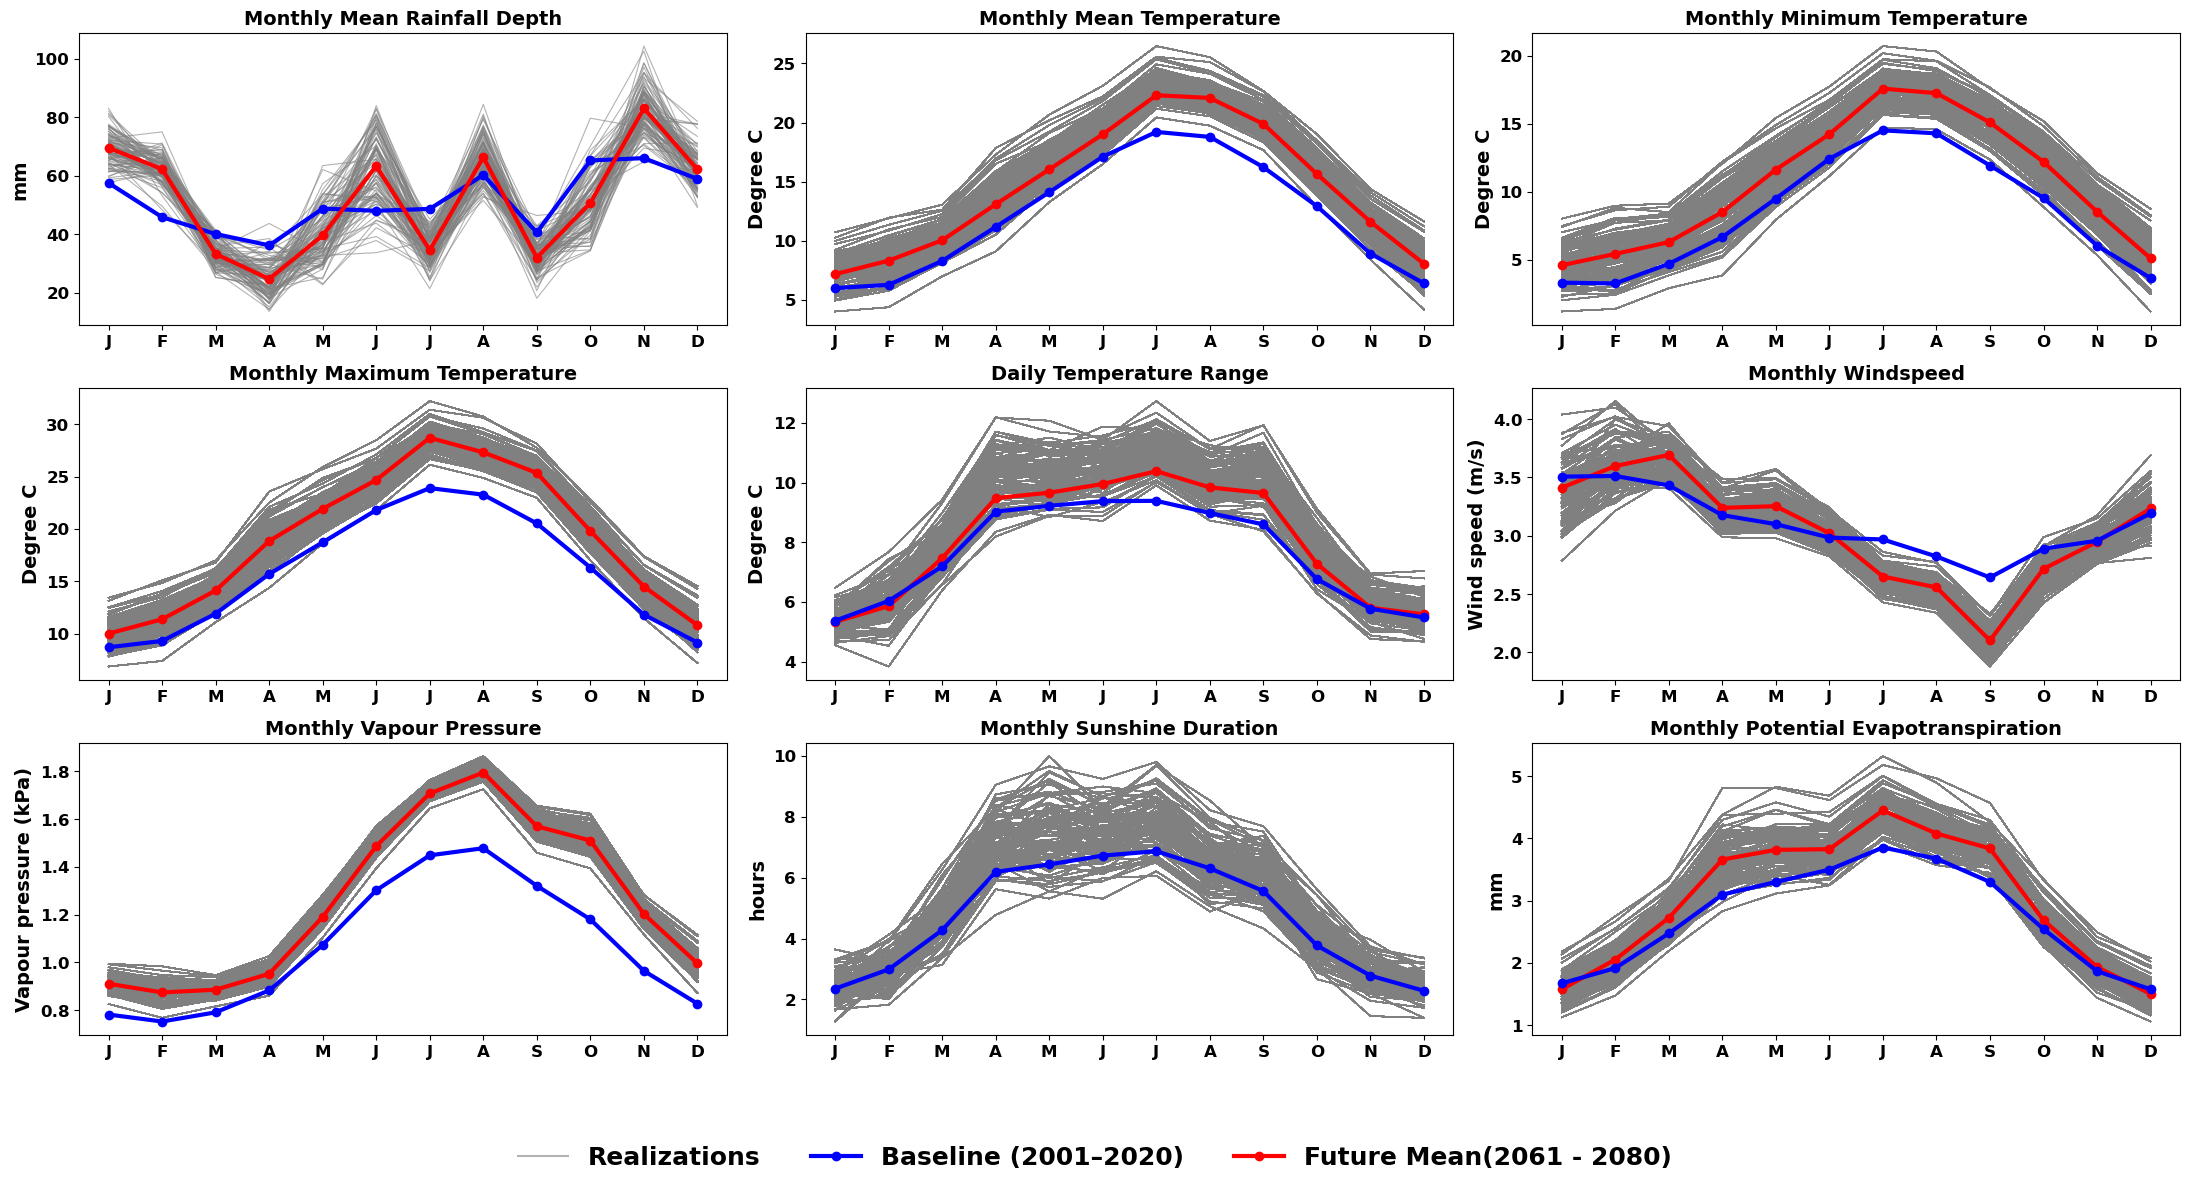

In [15]:
if SIMULATION_MODE == 'baseline':
    months = np.arange(1, 13)
    plt.rcParams['font.weight']='bold'
    month_labels = ["J","F","M","A","M","J","J","A","S","O","N","D"]
    fig, axes = plt.subplots(3,3, figsize=(22,12))
    axes = axes.flatten()

    # Rainfall 
    for col in real_cols:
        axes[0].plot(months, monthly_mean_real[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[0].plot(months,monthly_mean_real.drop('Month',axis=1).mean(axis=1).to_numpy(),'-o', color='green', linewidth=3)
    axes[0].plot(months,RAINOBS,'-o', color='blue', linewidth=3)
    axes[0].set_title('Monthly Mean Rainfall Depth', fontweight='bold',fontsize=14)
    axes[0].set_ylabel('mm',fontweight='bold',fontsize=14)

    # Mean Temperature
    for col in MONTHLY_TEMP_REAL.columns:
        axes[1].plot(months, MONTHLY_TEMP_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[1].plot(months,MONTHLY_TEMP_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[1].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'temp_avg', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[1].set_title('Monthly Mean Temperature', fontweight='bold',fontsize=14)
    axes[1].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # Minimum Temperature
    for col in MONTHLY_TEMPMIN_REAL.columns:
        axes[2].plot(months, MONTHLY_TEMPMIN_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[2].plot(months,MONTHLY_TEMPMIN_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[2].plot(months,MINMAXTEMP['tmin_mean'][(MINMAXTEMP['easting']==EASTING) & (MINMAXTEMP['northing']==NORTHING)].values ,'-o', color='blue', linewidth=3)
    axes[2].set_title('Monthly Minimum Temperature', fontweight='bold',fontsize=14)
    axes[2].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # Maximum Temperature
    for col in MONTHLY_TEMPMAX_REAL.columns:
        axes[3].plot(months, MONTHLY_TEMPMAX_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[3].plot(months,MONTHLY_TEMPMAX_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[3].plot(months,MINMAXTEMP['tmax_mean'][(MINMAXTEMP['easting']==EASTING) & (MINMAXTEMP['northing']==NORTHING)].values ,'-o', color='blue', linewidth=3)
    axes[3].set_title('Monthly Maximum Temperature', fontweight='bold',fontsize=14)
    axes[3].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # Daily Temperature Range
    for col in MONTHLY_DTR_REAL.columns:
        axes[4].plot(months, MONTHLY_DTR_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[4].plot(months,MONTHLY_DTR_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[4].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'dtr', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[4].set_title('Daily Temperature Range', fontweight='bold',fontsize=14)
    axes[4].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # WIND SPEED
    for col in MONTHLY_WSPD_REAL.columns:
        axes[5].plot(months, MONTHLY_WSPD_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[5].plot(months,MONTHLY_WSPD_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[5].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'wind_speed', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[5].set_title('Monthly Windspeed', fontweight='bold',fontsize=14)
    axes[5].set_ylabel('Wind speed (m/s)',fontweight='bold',fontsize=14)

    # VAPOUR PRESSURE
    for col in MONTHLY_VAPR_REAL.columns:
        axes[6].plot(months, MONTHLY_VAPR_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[6].plot(months,MONTHLY_VAPR_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[6].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'vap_press', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[6].set_title('Monthly Vapour Pressure', fontweight='bold',fontsize=14)
    axes[6].set_ylabel('Vapour pressure (kPa)',fontweight='bold',fontsize=14)

    # Sunshine Duration
    for col in MONTHLY_SDUR_REAL.columns:
        axes[7].plot(months, MONTHLY_SDUR_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[7].plot(months,MONTHLY_SDUR_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[7].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'sun_dur', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[7].set_title('Monthly Sunshine Duration', fontweight='bold',fontsize=14)
    axes[7].set_ylabel('hours',fontweight='bold',fontsize=14)

    for col in MONTHLY_PET_REAL.columns:
        axes[8].plot(months, MONTHLY_PET_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    # We dont have a relevant baseline for Potential Evapotranspiration
    axes[8].plot(months,MONTHLY_PET_REAL.mean(axis=1),'-o', color='green', linewidth=3)
    axes[8].set_title('Monthly Potential Evapotranspiration', fontweight='bold',fontsize=14)
    axes[8].set_ylabel('mm',fontweight='bold',fontsize=14)

    for ax in axes:
        ax.set_xticks(months)
        ax.set_xticklabels(month_labels)
        ax.tick_params(axis='both', labelsize=12)

    handles = [Line2D([0],[0], color='grey', alpha=0.6, linewidth=1.5,label='Realizations'),Line2D([0],[0], color='blue', marker='o', linewidth=3,label='HadUK Observed (2001–2020)'),
               Line2D([0],[0], color='green', marker='o', linewidth=3,label='WG_Average (2001–2020)')]
    fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,fontsize=18)
    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()
else:
    months = np.arange(1, 13)
    plt.rcParams['font.weight']='bold'
    month_labels = ["J","F","M","A","M","J","J","A","S","O","N","D"]
    fig, axes = plt.subplots(3,3, figsize=(22,12))
    axes = axes.flatten()

    # Rainfall 
    for col in real_cols:
        axes[0].plot(months, monthly_mean_real[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[0].plot(months,RAINOBS,'-o', color='blue', linewidth=3)
    axes[0].plot(months,monthly_mean_real.drop('Month',axis=1).mean(axis=1).to_numpy(),'-o', color='red', linewidth=3)
    axes[0].set_title('Monthly Mean Rainfall Depth', fontweight='bold',fontsize=14)
    axes[0].set_ylabel('mm',fontweight='bold',fontsize=14)

    # Mean Temperature
    for col in MONTHLY_TEMP_REAL.columns:
        axes[1].plot(months, MONTHLY_TEMP_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[1].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'temp_avg', 'mean'].values,'-o', color='red', linewidth=3)
    axes[1].plot(months,RAW_STATISTICS_PAST.loc[RAW_STATISTICS_PAST['variable'] == 'temp_avg', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[1].set_title('Monthly Mean Temperature', fontweight='bold',fontsize=14)
    axes[1].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # Minimum Temperature
    for col in MONTHLY_TEMPMIN_REAL.columns:
        axes[2].plot(months, MONTHLY_TEMPMIN_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[2].plot(months,MINMAXTEMP['tmin_mean'][(MINMAXTEMP['easting']==EASTING) & (MINMAXTEMP['northing']==NORTHING)].values ,'-o', color='blue', linewidth=3)
    axes[2].plot(months,MONTHLY_TEMPMIN_REAL.mean(axis=1),'-o', color='red', linewidth=3)
    axes[2].set_title('Monthly Minimum Temperature', fontweight='bold',fontsize=14)
    axes[2].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # Maximum Temperature
    for col in MONTHLY_TEMPMAX_REAL.columns:
        axes[3].plot(months, MONTHLY_TEMPMAX_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[3].plot(months,MINMAXTEMP['tmax_mean'][(MINMAXTEMP['easting']==EASTING) & (MINMAXTEMP['northing']==NORTHING)].values ,'-o', color='blue', linewidth=3)
    axes[3].plot(months,MONTHLY_TEMPMAX_REAL.mean(axis=1),'-o', color='red', linewidth=3)
    axes[3].set_title('Monthly Maximum Temperature', fontweight='bold',fontsize=14)
    axes[3].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # Daily Temperature Range
    for col in MONTHLY_DTR_REAL.columns:
        axes[4].plot(months, MONTHLY_DTR_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[4].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'dtr', 'mean'].values,'-o', color='red', linewidth=3)
    axes[4].plot(months,RAW_STATISTICS_PAST.loc[RAW_STATISTICS_PAST['variable'] == 'dtr', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[4].set_title('Daily Temperature Range', fontweight='bold',fontsize=14)
    axes[4].set_ylabel('Degree C',fontweight='bold',fontsize=14)

    # WIND SPEED
    for col in MONTHLY_WSPD_REAL.columns:
        axes[5].plot(months, MONTHLY_WSPD_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[5].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'wind_speed', 'mean'].values,'-o', color='red', linewidth=3)
    axes[5].plot(months,RAW_STATISTICS_PAST.loc[RAW_STATISTICS_PAST['variable'] == 'wind_speed', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[5].set_title('Monthly Windspeed', fontweight='bold',fontsize=14)
    axes[5].set_ylabel('Wind speed (m/s)',fontweight='bold',fontsize=14)

    # VAPOUR PRESSURE
    for col in MONTHLY_VAPR_REAL.columns:
        axes[6].plot(months, MONTHLY_VAPR_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[6].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'vap_press', 'mean'].values,'-o', color='red', linewidth=3)
    axes[6].plot(months,RAW_STATISTICS_PAST.loc[RAW_STATISTICS_PAST['variable'] == 'vap_press', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[6].set_title('Monthly Vapour Pressure', fontweight='bold',fontsize=14)
    axes[6].set_ylabel('Vapour pressure (kPa)',fontweight='bold',fontsize=14)

    # Sunshine Duration
    for col in MONTHLY_SDUR_REAL.columns:
        axes[7].plot(months, MONTHLY_SDUR_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    # Future projections of Sunshine Duration are unavailable with UKCP18
    axes[7].plot(months,RAW_STATISTICS.loc[RAW_STATISTICS['variable'] == 'sun_dur', 'mean'].values,'-o', color='blue', linewidth=3)
    axes[7].set_title('Monthly Sunshine Duration', fontweight='bold',fontsize=14)
    axes[7].set_ylabel('hours',fontweight='bold',fontsize=14)

    for col in MONTHLY_PET_REAL.columns:
        axes[8].plot(months, MONTHLY_PET_REAL[col],color='grey', alpha=0.6, linewidth=0.8)

    axes[8].plot(months,MONTHLY_PET_REAL.mean(axis=1),'-o', color='red', linewidth=3)
    # We dont have a relevant baseline for Potential Evapotranspiration, we take WG baseline averages for benchmarking
    axes[8].plot(months,PET_GRID_BASELINE,'-o', color='blue', linewidth=3)
    axes[8].set_title('Monthly Potential Evapotranspiration', fontweight='bold',fontsize=14)
    axes[8].set_ylabel('mm',fontweight='bold',fontsize=14)

    for ax in axes:
        ax.set_xticks(months)
        ax.set_xticklabels(month_labels)
        ax.tick_params(axis='both', labelsize=12)

    handles = [Line2D([0],[0], color='grey', alpha=0.6, linewidth=1.5,label='Realizations'),Line2D([0],[0], color='blue', marker='o', linewidth=3,label='Baseline (2001–2020)'),
               Line2D([0],[0], color='red', marker='o', linewidth=3,label='Future Mean'+'('+str(CP1)+' - '+str(CP2)+')')]
    fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,fontsize=18)
    fig.tight_layout(rect=[0, 0.10, 1, 1])
    plt.show()